# Apa Keluhan Utama Pelanggan Sunscreen?

Saya menemukan bahwa **Sunscreen** adalah kategori besar dengan ulasan negatif tertinggi (13,8%). Sekarang kita gali **teks ulasannya** untuk menjawab:

1. Keluhan apa yang paling sering muncul di ulasan negatif?
2. Apakah keluhannya berbeda menurut **jenis kulit**?
3. Apakah keluhan *white cast* dipengaruhi **warna kulit**? (penting untuk pasar Indonesia)
4. Produk sunscreen mana yang paling banyak dikeluhkan, dan karena apa?
5. **Rekomendasi**: seperti apa sunscreen ideal untuk brand lokal (Wardah/Emina)?

**Metode:** *keyword-based theme detection*. Setiap tema keluhan (misalnya "berminyak") punya daftar kata kunci. Sebuah ulasan dihitung mengeluhkan tema tersebut jika kata kuncinya muncul **tanpa didahului kata negasi** (no, not, doesn't, without, ...).

In [ ]:
from pathlib import Path
import re
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
from matplotlib.colors import LinearSegmentedColormap

ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
PROCESSED = ROOT / "data" / "processed"
FIG_DIR = ROOT / "reports" / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

reviews = pd.read_parquet(PROCESSED / "reviews_clean.parquet")
sun = reviews[reviews["secondary_category"] == "Sunscreen"].copy()

sun["text"] = (sun["review_title"].fillna("") + ". " + sun["review_text"].fillna("")).str.lower()
sun["group"] = np.select([sun["rating"] <= 2, sun["rating"] >= 4], ["negatif", "positif"], "netral")

print(f"Ulasan sunscreen: {len(sun):,} | Produk: {sun['product_id'].nunique()} | Brand: {sun['brand_name'].nunique()}")
sun["group"].value_counts()

Ulasan sunscreen: 41,100 | Produk: 108 | Brand: 41


group
positif    31934
negatif     5675
netral      3491
Name: count, dtype: int64

In [2]:
BLUE = "#2a78d6"; GREY = "#c9c8c1"; GREY_DARK = "#8a8984"
TEXT = "#0b0b0b"; TEXT_2 = "#52514e"; SURFACE = "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "font.size": 11, "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.edgecolor": "#d6d5ce", "axes.labelcolor": TEXT_2, "xtick.color": TEXT_2, "ytick.color": TEXT_2,
    "text.color": TEXT, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ebeae4", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight",
})
LABEL_BOX = dict(facecolor=SURFACE, edgecolor="none", pad=1)

def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png")
    print("Disimpan:", FIG_DIR / f"{name}.png")

Coba hitung berapa persen ulasan yang menyebut **"white cast"**:

In [14]:
sun.groupby("group")["text"].apply(lambda t: t.str.contains("white cast").mean()).map("{:.1%}".format)

group
negatif    14.0%
netral     18.1%
positif    19.0%
Name: text, dtype: str

**Lho, justru ulasan positif lebih sering menyebut "white cast"!** Kenapa? Karena pelanggan yang puas menulis *"**no** white cast"* atau *"**doesn't** leave a white cast"*.

Harus membedakan:
- **Keluhan**: "leaves a horrible white cast"
- **Pujian**: "no white cast at all"

## 2. Kamus tema keluhan

In [5]:
THEMES = {
    "Berminyak / lengket / berat": r"greas|oily(?!\s*(?:skin|and|/|-|,|t.zone|combo|or|prone|complexion|to))|shiny|\bshine\b|sticky|tacky|slick|heavy",
    "Jerawat / breakout":   r"break\s?out|broke (?:me )?out|breaking out|\bacne\b(?![\s-]*prone)|pimple|clog|cystic|whitehead|milia|\bbumps\b",
    "Pilling (menggumpal)": r"\bpill|\bpils\b|balls? up|rolls? off|crumbl",
    "White cast":           r"white[\s-]?cast|whitecast|chalky|ashy|ghostly|ghost|purple cast|gr[ae]y cast|white residue|leaves? (?:a |me )?(?:slight )?white",
    "Iritasi / perih":      r"\bburn(?:ing|ed|s)?\b|\bsting|\bitch|\brash|redness|irritat|allerg|react(?:ion|ed)",
    "Bikin kering":         r"\bdry(?:ing)?\b(?!\s*(?:skin|/|-|,|and|or|to|combo|sensitive))|flaky|flakiness|tight|dehydrat|parch",
    "Bau / wangi":          r"\bsmell|scent|fragranc|odor|odour|perfum|stink",
    "Harga / ukuran":       r"overpriced|expensive|pricey|waste of money|\bprice\b|tiny (?:bottle|tube)|small (?:bottle|tube)",
    "Perih di mata":        r"(?:eye|eyes)\W+(?:\w+\W+){0,4}(?:sting|burn|water|tear)|(?:sting|burn)\w*\W+(?:\w+\W+){0,4}eyes",
    "Tidak melindungi":     r"sunburn|sun burn|got burn|got burnt|still burn|burned me|didn.t protect|not protect",
}
# Kata negasi dalam 3-4 kata sebelum kata kunci -> bukan keluhan
NEGATION = re.compile(r"(?:\bno\b|\bnot\b|n't|n’t|\bwithout\b|\bzero\b|\bnever\b|\bnor\b|\bnon\b|\blittle\b|\bminimal\b|\bany\b)\W+(?:\w+\W+){0,3}$")

def is_complaint(text, pattern):
    for m in re.finditer(pattern, text):
        before = text[max(0, m.start() - 40):m.start()]
        if not NEGATION.search(before):
            return True
    return False

for theme, pattern in THEMES.items():
    sun[theme] = sun["text"].map(lambda t, p=pattern: is_complaint(t, p))
THEME_COLS = list(THEMES)
print("Selesai menandai", len(THEME_COLS), "tema")

Selesai menandai 10 tema


### Validasi: baca contoh ulasan
Metode berbasis kata kunci **harus dicek manual**. Kita ambil contoh acak ulasan negatif yang ditandai per tema, lalu baca apakah benar keluhan.

In [6]:
neg = sun[sun["group"] == "negatif"]
pos = sun[sun["group"] == "positif"]
for theme in ["Berminyak / lengket / berat", "Pilling (menggumpal)", "White cast"]:
    print(f"\n=== {theme} ===")
    for t in neg.loc[neg[theme], "text"].sample(3, random_state=3):
        print(" -", t[:200])


=== Berminyak / lengket / berat ===
 - leaves your face greasy!. i really wanted to love this but it left my face looking so greasy. it was a semi-fine spray but you could still see every single spot on my face. the second time i tried it 
 - . i’ve been using this for 3 days now from a sample that i received and i have to say that i would not purchase it. it is hydrating but it is very oily. my skin broke out after i started and very shin
 - so light but oh so oily. i got a sample of this and was so excited to try it. sadly it didn’t meet my expectations. it was very lightweight for application and didn’t seem to make me too ashy (i did p

=== Pilling (menggumpal) ===
 - . was really excited to try this because so many people told me it was great. when i used it the first time my skin looked great but that was the only time. every other time i have used it (maybe abou
 - pills, smelly, just no thanks.. giving this 2 stars because there is no white cast but that’s about the only good 

> **Keterbatasan (wajib ditulis di portofolio):** metode kata kunci tidak sempurna. Masih ada salah tangkap, misalnya "*I hate sunscreens that leave a white cast, but this one is great*". Karena itu kita **membandingkan ulasan negatif vs positif**. Kesalahan seperti ini terjadi di kedua kelompok, jadi selisihnya tetap bermakna.

## Keluhan apa yang paling sering muncul?
Untuk tiap tema kita hitung **% ulasan negatif** yang menyebutnya, lalu bandingkan dengan **% ulasan positif**.
**Lift** = % di negatif ÷ % di positif. Lift tinggi berarti tema itu **khas ulasan negatif** (penyebab kecewa).

In [7]:
theme_tbl = pd.DataFrame({
    "pct_ulasan_negatif": neg[THEME_COLS].mean(),
    "pct_ulasan_positif": pos[THEME_COLS].mean(),
})
theme_tbl["lift"] = theme_tbl["pct_ulasan_negatif"] / theme_tbl["pct_ulasan_positif"]
theme_tbl = theme_tbl.sort_values("pct_ulasan_negatif", ascending=False)
print(f"Ulasan negatif yang menyebut minimal 1 tema: {neg[THEME_COLS].any(axis=1).mean():.1%}")
theme_tbl.style.format({"pct_ulasan_negatif": "{:.1%}", "pct_ulasan_positif": "{:.1%}", "lift": "{:.1f}x"})

Ulasan negatif yang menyebut minimal 1 tema: 78.7%


,pct_ulasan_negatif,pct_ulasan_positif,lift
Berminyak / lengket / berat,32.4%,15.1%,2.1x
Jerawat / breakout,15.1%,4.5%,3.4x
Bau / wangi,15.1%,22.8%,0.7x
Pilling (menggumpal),14.0%,1.6%,8.6x
White cast,13.5%,5.8%,2.3x
Iritasi / perih,11.8%,5.1%,2.3x
Harga / ukuran,8.2%,6.4%,1.3x
Bikin kering,6.5%,3.2%,2.0x
Perih di mata,2.9%,0.9%,3.4x
Tidak melindungi,2.8%,0.9%,3.0x


Disimpan: c:\Users\Nakata\Documents\Data Analyst\sephora-skincare-analysis\reports\figures\06_sunscreen_complaints.png


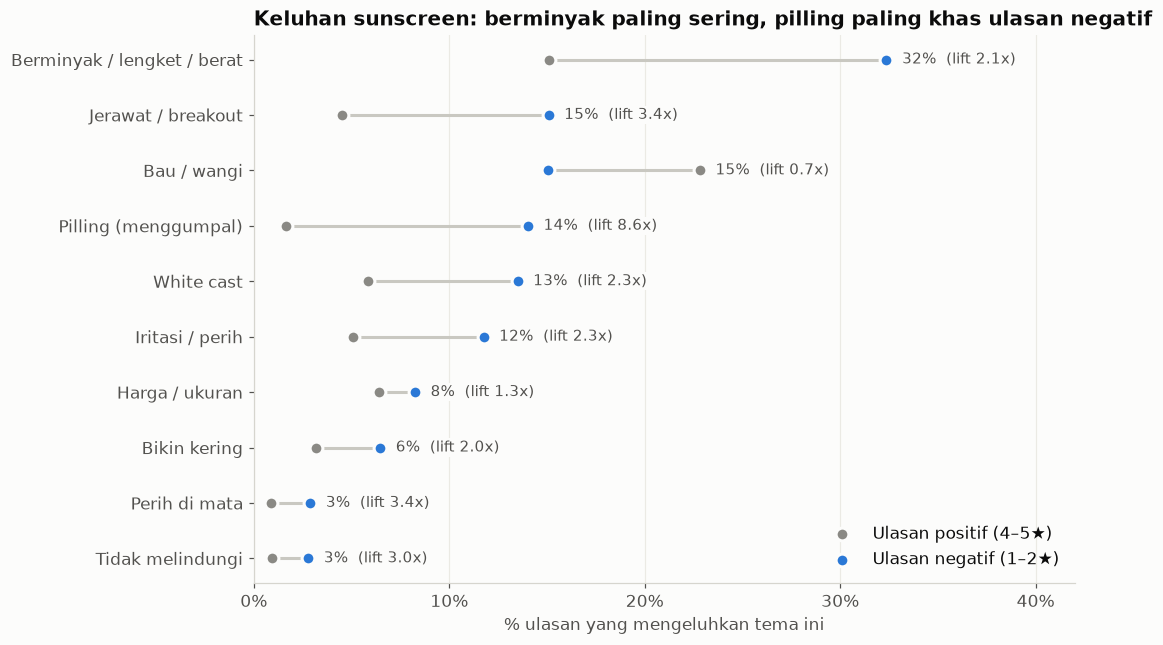

In [8]:
plot_df = theme_tbl.sort_values("pct_ulasan_negatif")
y = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(10, 6))
ax.hlines(y, plot_df["pct_ulasan_positif"], plot_df["pct_ulasan_negatif"], color=GREY, linewidth=2, zorder=1)
ax.scatter(plot_df["pct_ulasan_positif"], y, s=70, color=GREY_DARK, zorder=3, label="Ulasan positif (4–5★)",
           edgecolor=SURFACE, linewidth=2)
ax.scatter(plot_df["pct_ulasan_negatif"], y, s=70, color=BLUE, zorder=3, label="Ulasan negatif (1–2★)",
           edgecolor=SURFACE, linewidth=2)
for i, (n, l) in enumerate(zip(plot_df["pct_ulasan_negatif"], plot_df["lift"])):
    x = max(n, plot_df["pct_ulasan_positif"].iloc[i])
    ax.text(x + 0.008, i, f"{n:.0%}  (lift {l:.1f}x)", va="center", fontsize=10, color=TEXT_2, bbox=LABEL_BOX)
ax.set_yticks(y, plot_df.index)
ax.set_xlim(0, 0.42)
ax.xaxis.set_major_locator(mtick.MultipleLocator(0.1))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("% ulasan yang mengeluhkan tema ini")
ax.set_title("Keluhan sunscreen: berminyak paling sering, pilling paling khas ulasan negatif")
ax.legend(loc="lower right", frameon=False)
ax.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "06_sunscreen_complaints"); plt.show()

**Insight:**
- **Berminyak / lengket / berat** adalah keluhan #1: muncul di **~1 dari 3** ulasan negatif.
- **Jerawat (15%)**, **pilling (14%)**, dan **white cast (13,5%)** menyusul.
- **Pilling** punya *lift* tertinggi (~9x). Hampir tidak pernah disebut di ulasan positif, jadi kalau sunscreen menggumpal, pelanggan hampir pasti kecewa. Ini masalah besar bagi pengguna yang memakai makeup di atas sunscreen.
- **Bau / wangi** lift-nya < 1, artinya justru lebih sering dibahas di ulasan positif ("wanginya enak"). Jadi aroma **bukan** penyebab utama kekecewaan.

## Apakah keluhan berbeda menurut jenis kulit?
Persentase di bawah dihitung **di antara ulasan negatif** tiap jenis kulit.

Disimpan: c:\Users\Nakata\Documents\Data Analyst\sephora-skincare-analysis\reports\figures\07_complaints_by_skin_type.png


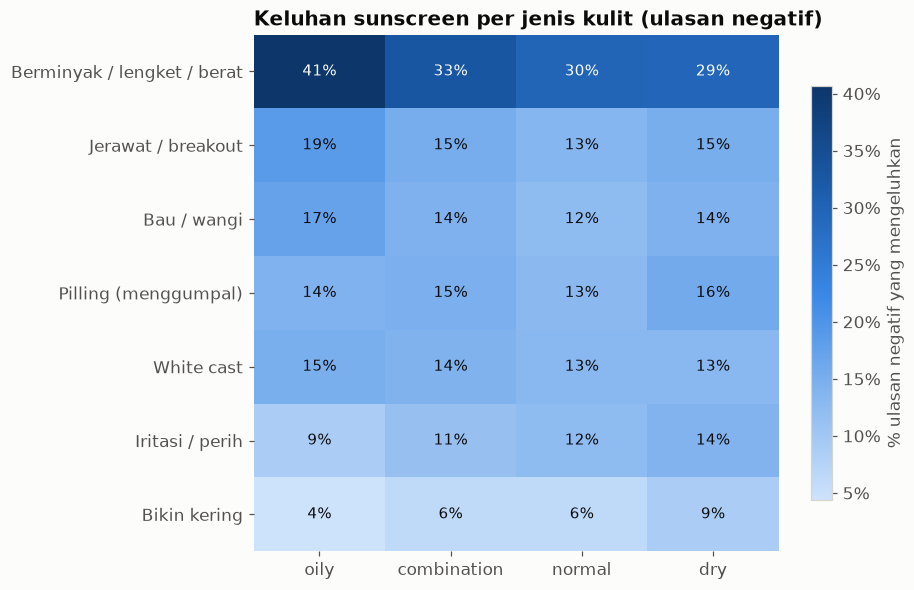

In [9]:
skin = (neg[neg["skin_type"] != "unknown"]
        .groupby("skin_type")[THEME_COLS].mean()
        .T[["oily", "combination", "normal", "dry"]])
skin = skin.loc[theme_tbl.index[:6].tolist() + ["Bikin kering"]]

blues = LinearSegmentedColormap.from_list("blues", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
fig, ax = plt.subplots(figsize=(8.5, 5.5))
im = ax.imshow(skin.values, cmap=blues, aspect="auto")
ax.set_xticks(range(skin.shape[1]), skin.columns)
ax.set_yticks(range(skin.shape[0]), skin.index)
ax.grid(False)
thr = skin.values.min() + (skin.values.max() - skin.values.min()) * 0.5
for i in range(skin.shape[0]):
    for j in range(skin.shape[1]):
        v = skin.values[i, j]
        ax.text(j, i, f"{v:.0%}", ha="center", va="center", fontsize=10, color="white" if v > thr else TEXT)
for s in ax.spines.values():
    s.set_visible(False)
cbar = fig.colorbar(im, ax=ax, format=mtick.PercentFormatter(1, decimals=0), shrink=0.8)
cbar.set_label("% ulasan negatif yang mengeluhkan")
ax.set_title("Keluhan sunscreen per jenis kulit (ulasan negatif)")
fig.tight_layout(); save(fig, "07_complaints_by_skin_type"); plt.show()

**Insight:**
- **Kulit berminyak (oily):** **41%** ulasan negatifnya mengeluhkan sunscreen yang berminyak/berat (jenis kulit lain 29–33%), dan keluhan **jerawat** juga paling tinggi (19%).
- **Kulit kering (dry):** lebih sering mengeluhkan **iritasi/perih** (14% vs 9% di kulit berminyak) dan sedikit lebih sering "bikin kering" (9% vs ~6%).
- Keluhan **berminyak** tetap #1 di semua jenis kulit, jadi tekstur ringan adalah kebutuhan umum, bukan hanya untuk kulit berminyak.
- Artinya, **satu formula sulit memuaskan semua**. Varian per jenis kulit (gel matte untuk berminyak, formula lembut & lembap untuk kering/sensitif) masuk akal.

## White cast & warna kulit
Ini bagian yang paling relevan untuk Indonesia, di mana mayoritas konsumen berkulit **medium hingga sawo matang (tan)**.
Warna kulit dikelompokkan menjadi 4 grup; warna kulit dengan data sangat sedikit (olive, porcelain, "not sure") tidak dipakai.

In [10]:
tone_map = {
    "fair": "Terang", "fairLight": "Terang", "light": "Terang",
    "lightMedium": "Medium", "medium": "Medium",
    "mediumTan": "Sawo matang", "tan": "Sawo matang",
    "deep": "Gelap", "rich": "Gelap", "dark": "Gelap",
}
order = ["Terang", "Medium", "Sawo matang", "Gelap"]
neg_tone = neg.assign(tone_group=neg["skin_tone"].map(tone_map)).dropna(subset=["tone_group"])
tone_tbl = (neg_tone.groupby("tone_group")
            .agg(jumlah_ulasan_negatif=("White cast", "size"), pct_keluhan_white_cast=("White cast", "mean"))
            .loc[order])
tone_tbl

,jumlah_ulasan_negatif,pct_keluhan_white_cast
tone_group,,
Terang,3002,0.109927
Medium,1422,0.142053
Sawo matang,564,0.232270
Gelap,156,0.391026


Disimpan: c:\Users\Nakata\Documents\Data Analyst\sephora-skincare-analysis\reports\figures\08_white_cast_by_skin_tone.png


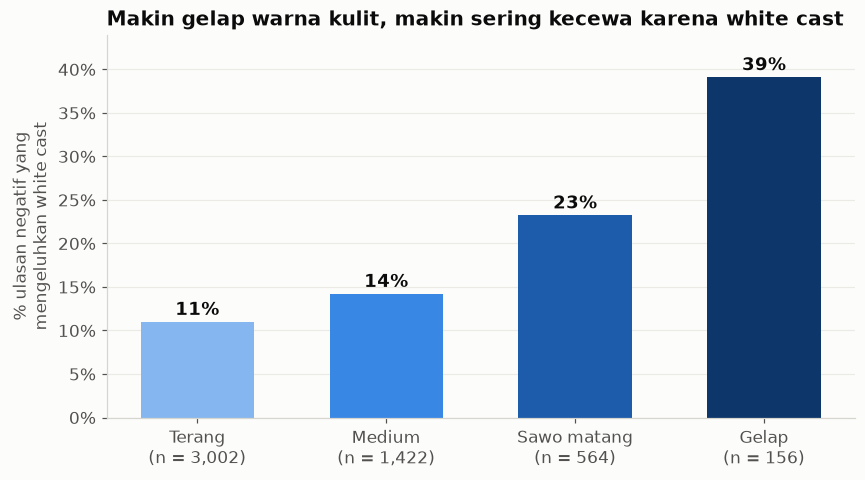

In [11]:
ramp = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]   # makin gelap = makin gelap warna kulit
fig, ax = plt.subplots(figsize=(8, 4.5))
xlabels = [f"{g}\n(n = {n:,})" for g, n in zip(tone_tbl.index, tone_tbl["jumlah_ulasan_negatif"])]
ax.bar(xlabels, tone_tbl["pct_keluhan_white_cast"], color=ramp, width=0.6)
for i, v in enumerate(tone_tbl["pct_keluhan_white_cast"]):
    ax.text(i, v + 0.008, f"{v:.0%}", ha="center", fontsize=12, fontweight="bold", color=TEXT)
ax.set_ylim(0, 0.44)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_ylabel("% ulasan negatif yang\nmengeluhkan white cast")
ax.set_title("Makin gelap warna kulit, makin sering kecewa karena white cast")
ax.grid(axis="x", visible=False)
fig.tight_layout(); save(fig, "08_white_cast_by_skin_tone"); plt.show()

**Insight:**
- Pada kulit **terang**, hanya ~11% ulasan negatif yang mengeluhkan white cast. Pada kulit **sawo matang** angkanya naik menjadi **~23%** (2x lipat), dan di kulit **gelap** ~39%.
- Sunscreen yang ada di pasar (data Sephora/AS) masih banyak yang **tidak cocok untuk kulit lebih gelap**.

**Relevansi untuk Indonesia:** konsumen Indonesia mayoritas berkulit medium–sawo matang. Sunscreen yang **benar-benar tanpa white cast di kulit sawo matang** adalah pembeda yang kuat.

Jumlah ulasan untuk kulit gelap lebih sedikit (n kecil), jadi angkanya kurang stabil, tetapi polanya konsisten naik.

## Produk sunscreen mana yang paling banyak dikeluhkan?
Hanya produk dengan **≥ 1.000 ulasan** yang dimasukkan supaya adil.

In [12]:
prod = (sun.groupby(["brand_name", "product_name"])
        .agg(jumlah_ulasan=("rating", "size"), pct_negatif=("rating", lambda r: (r <= 2).mean()))
        .query("jumlah_ulasan >= 1000")
        .sort_values("pct_negatif", ascending=False)
        .reset_index())

# Keluhan paling sering per produk (di antara ulasan negatifnya)
top_issue = (neg.groupby("product_name")[THEME_COLS].mean()
             .apply(lambda row: f"{row.idxmax()} ({row.max():.0%})", axis=1))
prod["keluhan_utama"] = prod["product_name"].map(top_issue)
prod.style.format({"pct_negatif": "{:.1%}", "jumlah_ulasan": "{:,}"})

,brand_name,product_name,jumlah_ulasan,pct_negatif,keluhan_utama
0,Drunk Elephant,Umbra Sheer Physical Daily Defense SPF 30,"1,361",33.3%,Berminyak / lengket / berat (38%)
1,Glow Recipe,Watermelon Glow Niacinamide Sunscreen SPF 50,"1,295",25.4%,Pilling (menggumpal) (64%)
2,Supergoop!,Mini Glowscreen Sunscreen SPF 40 PA+++ with Hyaluronic Acid + Niacinamide,"1,455",19.7%,Berminyak / lengket / berat (27%)
3,Supergoop!,PLAY Everyday Sunscreen Lotion SPF 50 PA++++,"1,058",16.3%,Berminyak / lengket / berat (56%)
4,Supergoop!,Glowscreen Sunscreen SPF 40 PA+++ with Hyaluronic Acid + Niacinamide,"2,065",15.3%,Berminyak / lengket / berat (24%)
5,Supergoop!,Unseen Sunscreen SPF 40 PA+++,"3,261",13.9%,Jerawat / breakout (38%)
6,innisfree,Daily UV Defense Invisible Broad Spectrum SPF 36 Sunscreen,"1,464",6.9%,Jerawat / breakout (48%)
7,Shiseido,Urban Environment Oil-Free Sunscreen Broad-Spectrum SPF 42,"1,343",4.3%,White cast (47%)
8,Shiseido,Ultimate Sun Protector Lotion SPF 50+ Sunscreen,"2,937",3.9%,Berminyak / lengket / berat (63%)
9,Shiseido,Clear Sunscreen Stick SPF 50+,"1,529",1.8%,Berminyak / lengket / berat (39%)


Disimpan: c:\Users\Nakata\Documents\Data Analyst\sephora-skincare-analysis\reports\figures\09_sunscreen_products.png


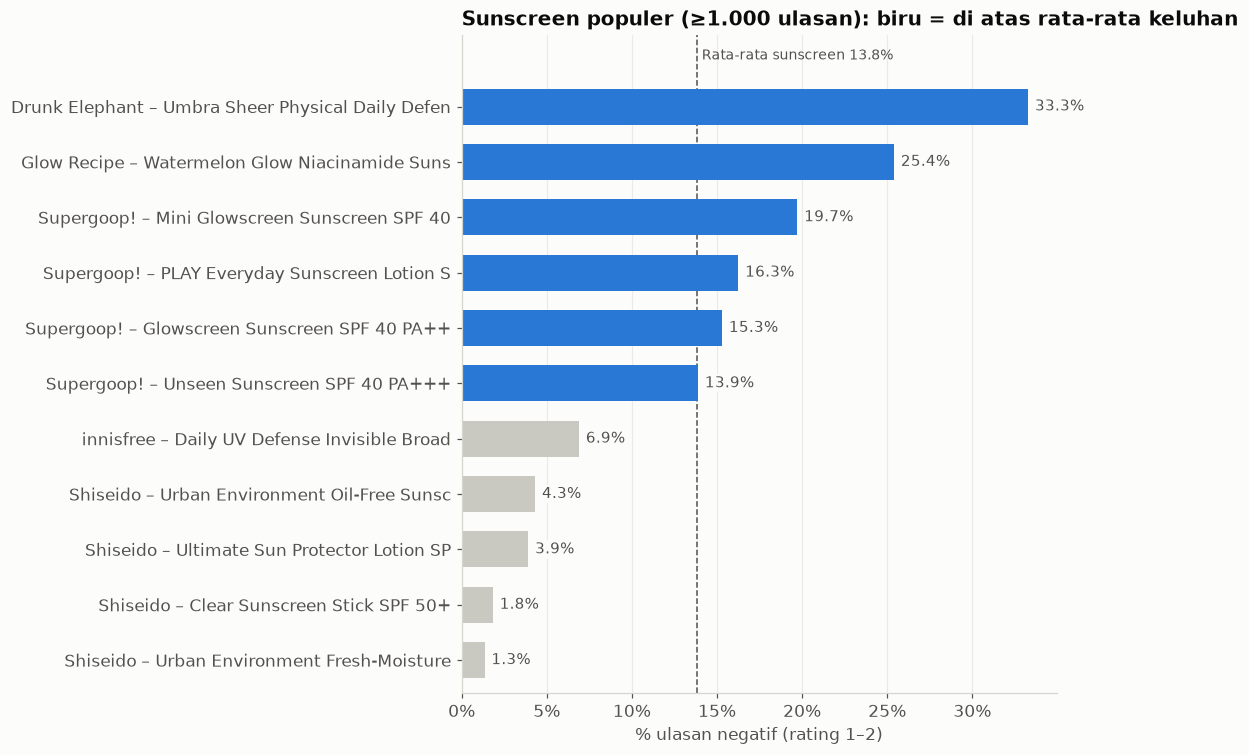

In [13]:
plot_df = prod.sort_values("pct_negatif")
short = (plot_df["brand_name"] + " – " + plot_df["product_name"].str.slice(0, 32)).values
avg = (sun["rating"] <= 2).mean()
colors = [BLUE if v > avg else GREY for v in plot_df["pct_negatif"]]

fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(short, plot_df["pct_negatif"], color=colors, height=0.65)
for i, v in enumerate(plot_df["pct_negatif"]):
    ax.text(v + 0.004, i, f"{v:.1%}", va="center", fontsize=10, color=TEXT_2, bbox=LABEL_BOX)
ax.axvline(avg, color=TEXT_2, linestyle="--", linewidth=1, zorder=0)
ax.set_ylim(-0.6, len(plot_df) + 0.3)
ax.text(avg + 0.003, len(plot_df) - 0.15, f"Rata-rata sunscreen {avg:.1%}", fontsize=9, color=TEXT_2)
ax.xaxis.set_major_locator(mtick.MultipleLocator(0.05))
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1, decimals=0))
ax.set_xlabel("% ulasan negatif (rating 1–2)")
ax.set_title("Sunscreen populer (≥1.000 ulasan): biru = di atas rata-rata keluhan")
ax.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "09_sunscreen_products"); plt.show()

**Insight:**
- Rentang kepuasan antar-produk **sangat lebar**: dari ~1% sampai ~33% ulasan negatif. Kategori sunscreen bukan "jelek semua"; ada produk yang berhasil.
- Dua produk dengan keluhan tertinggi punya masalah yang berbeda. **Drunk Elephant Umbra** (33%) paling sering dikeluhkan **berminyak/berat** (38% ulasan negatifnya), sedangkan **Glow Recipe Watermelon** (25%) didominasi **pilling** (64% ulasan negatifnya!).
- Untuk 4 dari 6 produk di atas rata-rata, keluhan utamanya adalah **berminyak/berat**, sejalan dengan temuan di bagian 3.
- **Shiseido** konsisten paling rendah keluhannya. Produk ini bisa jadi *benchmark* untuk dipelajari (tekstur, klaim, formula).

## Rekomendasi untuk brand lokal (contoh: Wardah / Emina)

Berdasarkan 41 ribu ulasan sunscreen, inilah **"product brief"** sunscreen yang menjawab keluhan terbesar:

| Prioritas | Keluhan dari data | Rekomendasi produk |
|---|---|---|
| 1 | Berminyak / berat (~1 dari 3 ulasan negatif; 41% di kulit berminyak) | Tekstur **ringan, gel/fluid, hasil akhir matte** untuk kulit berminyak dan iklim tropis |
| 2 | White cast naik tajam di kulit sawo matang & gelap | **Tanpa white cast di kulit sawo matang** (filter kimia/hibrid atau mineral ber-tint); uji pada warna kulit lokal |
| 3 | Pilling (lift ~9x, paling khas ulasan negatif) | **Tidak menggumpal saat dilapis makeup**; komunikasikan "makeup-friendly" |
| 4 | Jerawat (tertinggi di kulit berminyak) | Klaim **non-comedogenic** yang teruji |
| 5 | Kulit kering lebih sering mengeluh iritasi/perih & kering | Varian **lembut & melembapkan** untuk kulit kering/sensitif |

**Pesan utama:** pelanggan tidak kecewa karena SPF-nya, tetapi karena **pengalaman pemakaian** (tekstur, white cast, cocok dengan makeup). Brand yang menang di aspek sensorik akan menang di kategori ini.

### Keterbatasan analisis
- Data berasal dari **Sephora (pasar AS)**, bukan Indonesia. Pola keluhan diasumsikan serupa, tetapi perlu divalidasi dengan data lokal (misalnya ulasan e-commerce Indonesia).
- Deteksi tema berbasis kata kunci, jadi masih ada salah tangkap. Untuk analisis lanjutan bisa memakai model NLP (*sentiment/aspect-based*).
- Pengulas Sephora tidak mewakili seluruh konsumen (*self-selection bias*).